In [19]:
import pandas as pd
import numpy as np
import sys

metadata_fname = "../data/2024-0814-LDXray-0to75cGy-pelt-metadata_AZ.tsv"
quants_fname = "../quant-reports/TRX-unimputed-peptides-report.csv"
targets_fname = "../data/targets.tsv"

metadata = pd.read_csv(metadata_fname, sep='\t', na_values=['na'])
data = pd.read_csv(quants_fname)
data = data.fillna(0)
targets = pd.read_csv(targets_fname, sep='\t')

# Print original shape
print("Original data shape:", data.shape)

# Filter out rows where Protein column is "Decoys"
data = data[data['Protein'] != "Decoys"]

protein_names = data['Protein'].values
print("Metadata shape:", metadata.shape)
print("Data shape after removing Decoys:", data.shape)

Original data shape: (59007, 99)
Metadata shape: (96, 13)
Data shape after removing Decoys: (29503, 99)


Data shape: (80, 29503)
Doses: [ 0  0  0  0  0  0  0  0  0  0  0  0 75 75 75 75 75 75 65 65 65 65 55 55
 55 55 45 45 45 45 35 35 35 35 25 25 25 25 15 15 15 15  5  5  5  5 75 75
 75 75 75 75 65 65 65 65 55 55 55 55 45 45 45 45 35 35 35 35 25 25 25 25
 15 15 15 15  5  5  5  5]


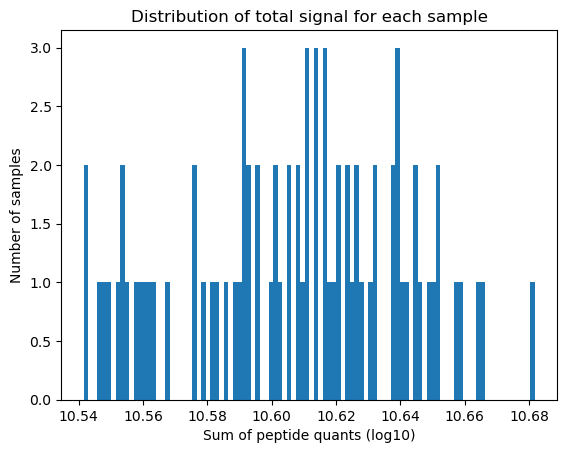

In [20]:
import matplotlib.pyplot as plt
import re

valid_replicates = metadata[
    (metadata['Target Dose_cGy'].notna()) & 
    (metadata['Target Dose_cGy'] != 'pool')
]['Replicate'].tolist()

X = []
rad = []
rates = []

# Get all data columns that contain "Normalized Area"
normalized_columns = [col for col in data.columns if "Normalized Area" in col]

# Process each valid replicate
for replicate_name in valid_replicates:
    # Extract the identifier from the end of the replicate name (e.g., "B03-413-15")
    match = re.search(r'([A-Z]\d{2}-\d{3}-\d{2})$', replicate_name)
    if not match:
        continue
    
    replicate_id = match.group(1)  # This would extract "B03-413-15"
    
    # Look for this ID in the column names
    for column in normalized_columns:
        if replicate_id in column:
            # Found a match between the replicate ID and a column
            s_rad = metadata[metadata['Replicate'] == replicate_name]['Target Dose_cGy'].values[0]
            s_rate = metadata[metadata['Replicate'] == replicate_name]['Dose Rate'].values[0]
            rad.append(int(s_rad))
            rates.append(s_rate)
            X.append(data[column].values)
            break  # Found the matching column, move to next replicate

X = np.array(X)
rad = np.array(rad)
rates = np.array(rates)
print("Data shape:", X.shape)
print("Doses:", rad)
total_signal = np.sum(X, axis=1)
plt.hist(np.log10(total_signal), bins=100)
plt.title('Distribution of total signal for each sample')
plt.ylabel('Number of samples')
plt.xlabel('Sum of peptide quants (log10)')
plt.show()

/tmp/ipykernel_1697953/1817144224.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([log_original, log_imputed], labels=["Original", "Imputed"])


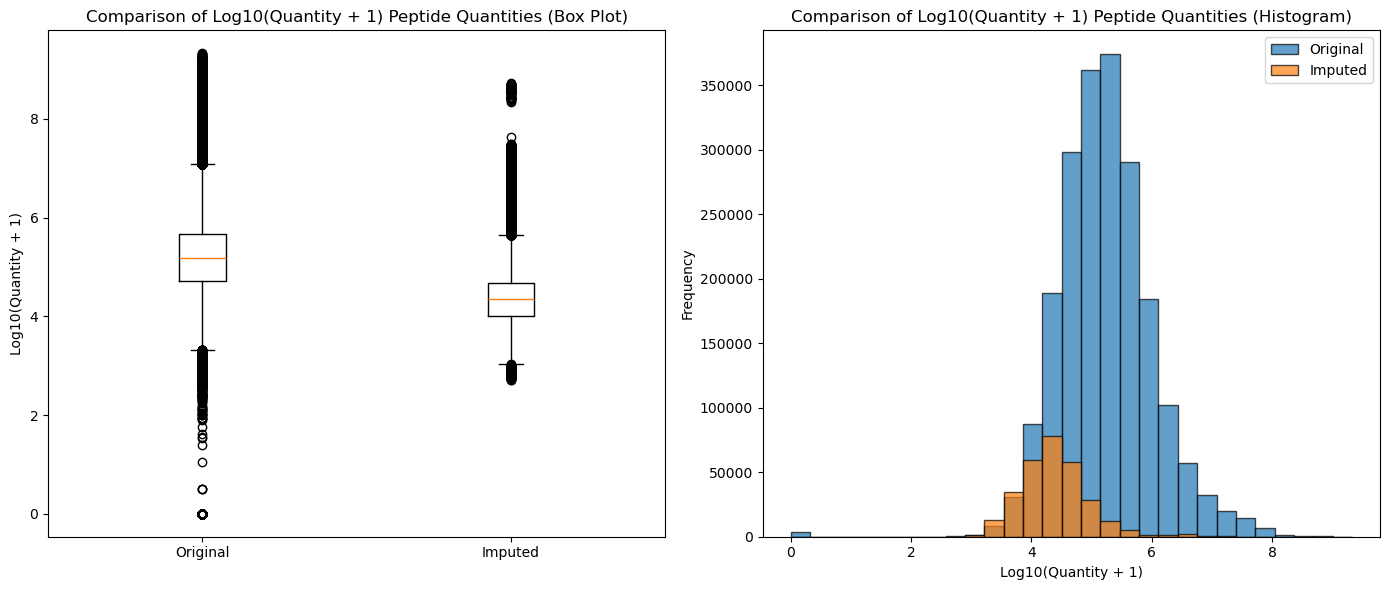

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer

# Replace 0s in X with np.nan for imputation
X[X == 0] = np.nan
nan_columns = np.isnan(X).all(axis=0)

if nan_columns.any():
    X[:, nan_columns] = 0  # Replace entirely missing columns with zeros

# Apply KNN imputation
imputer = KNNImputer(n_neighbors=3, weights="distance")
imputed_X = imputer.fit_transform(X)
#imputed_X = X.copy()
imputed_X[np.isnan(imputed_X)] = 0

# Identify the imputed values
imputed_mask = np.isnan(X)  # True for values that were originally NaN

# Log10-transform original non-missing and imputed values (log10(x + 1))
log_original = np.log10(X[~imputed_mask] + 1)  # Original, non-missing log10(x + 1)
log_imputed = np.log10(imputed_X[imputed_mask] + 1)  # Log10(x + 1) of imputed values

# Generate box plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].boxplot([log_original, log_imputed], labels=["Original", "Imputed"])
axes[0].set_title("Comparison of Log10(Quantity + 1) Peptide Quantities (Box Plot)")
axes[0].set_ylabel("Log10(Quantity + 1)")

# Generate histograms
bins = np.linspace(min(log_original.min(), log_imputed.min()), 
                   max(log_original.max(), log_imputed.max()), 30)
axes[1].hist(log_original, bins=bins, alpha=0.7, label="Original", edgecolor='black')
axes[1].hist(log_imputed, bins=bins, alpha=0.7, label="Imputed", edgecolor='black')
axes[1].set_title("Comparison of Log10(Quantity + 1) Peptide Quantities (Histogram)")
axes[1].set_xlabel("Log10(Quantity + 1)")
axes[1].set_ylabel("Frequency")
axes[1].legend()

plt.tight_layout()
plt.show()

In [22]:
print(f"X shape: {X.shape}")
print(f"imputed_X shape: {imputed_X.shape}")
print(f"protein_names length: {len(protein_names)}")

X shape: (80, 29503)
imputed_X shape: (80, 29503)
protein_names length: 29503


In [23]:
unique_proteins, protein_indices = np.unique(protein_names, return_inverse=True)

# Initialize the protein_X array
protein_X = np.zeros((imputed_X.shape[0], len(unique_proteins)))

# Sum values of peptides belonging to the same protein
for protein_idx in range(len(unique_proteins)):
    # Identify the peptide columns corresponding to the current protein
    peptide_columns = np.where(protein_indices == protein_idx)[0]
    # Sum the values across the identified columns for each sample
    protein_X[:, protein_idx] = imputed_X[:, peptide_columns].sum(axis=1)

# Update protein_names to match the new columns
protein_names = unique_proteins

X = protein_X

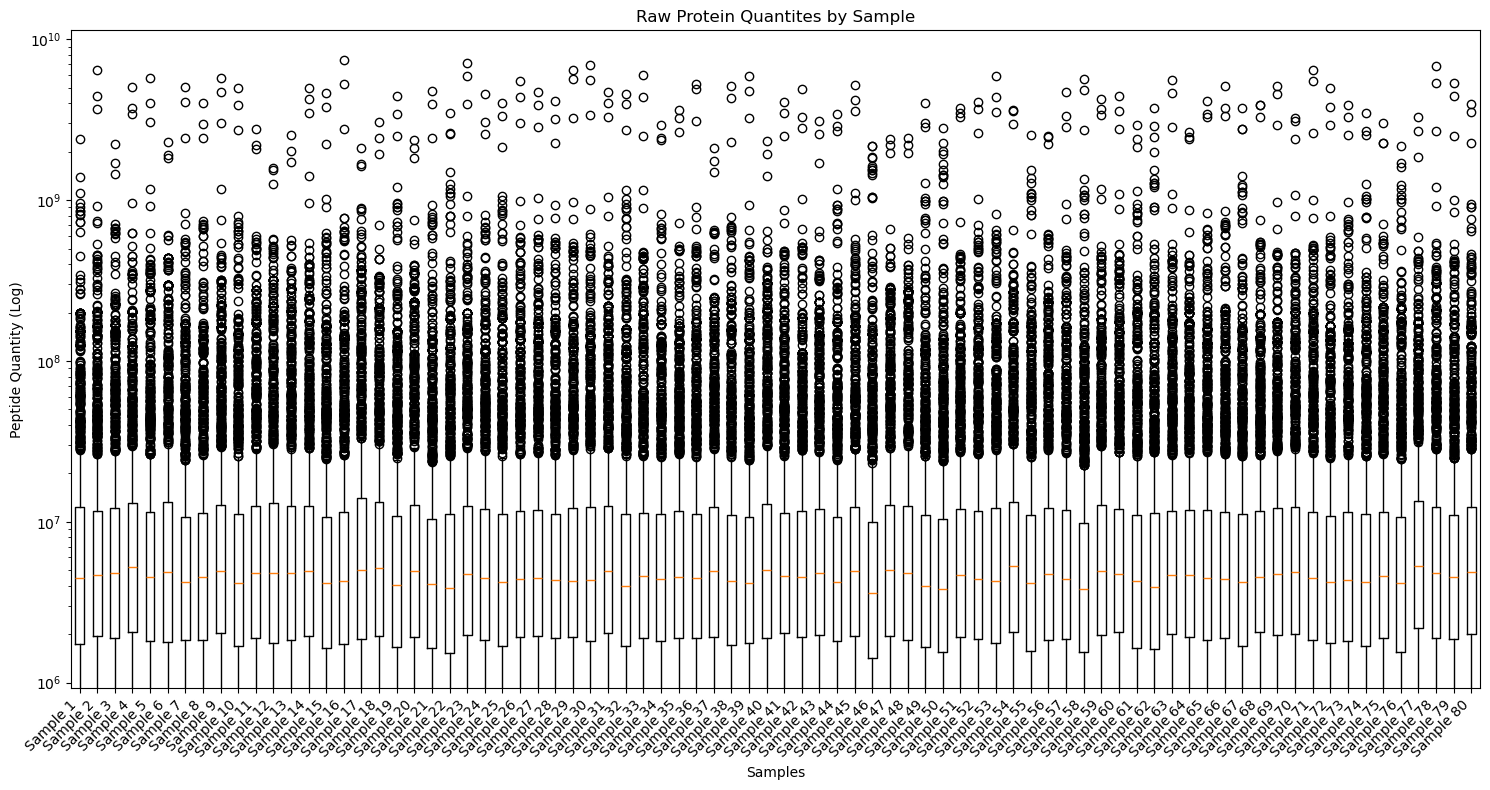

In [24]:
# Create the box plot
plt.figure(figsize=(15, 8))
plt.boxplot(X.T)  # Transpose the data

plt.title('Raw Protein Quantites by Sample')
plt.xlabel('Samples')
plt.ylabel('Peptide Quantity (Log)')
plt.xticks(range(1, X.shape[0] + 1), [f'Sample {i+1}' for i in range(X.shape[0])], rotation=45, ha='right')

# Use log scale for y-axis as peptide quantities often span several orders of magnitude
plt.yscale('log')

plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.show()

In [25]:
def mad_row_normalize(df):

    row_medians = df.median(axis=1) # medians for each row

    # Calculate the MAD for each row
    def mad(row):
        median = np.median(row)
        return np.median(np.abs(row - median))

    row_mads = df.apply(mad, axis=1)

    # Normalize each row by subtracting the median and dividing by the MAD
    df_normalized = df.sub(row_medians, axis=0).div(row_mads, axis=0)

    return df_normalized

labeled_X_log = np.log1p(X)
labeled_X_median_normalized = mad_row_normalize(pd.DataFrame(labeled_X_log))
print(labeled_X_median_normalized.shape)  # Should still be (N, M)

labeled_X_scaled = labeled_X_median_normalized
labeled_X_scaled = labeled_X_scaled.to_numpy()

X = labeled_X_scaled
# X = np.log1p(X)

(80, 1306)


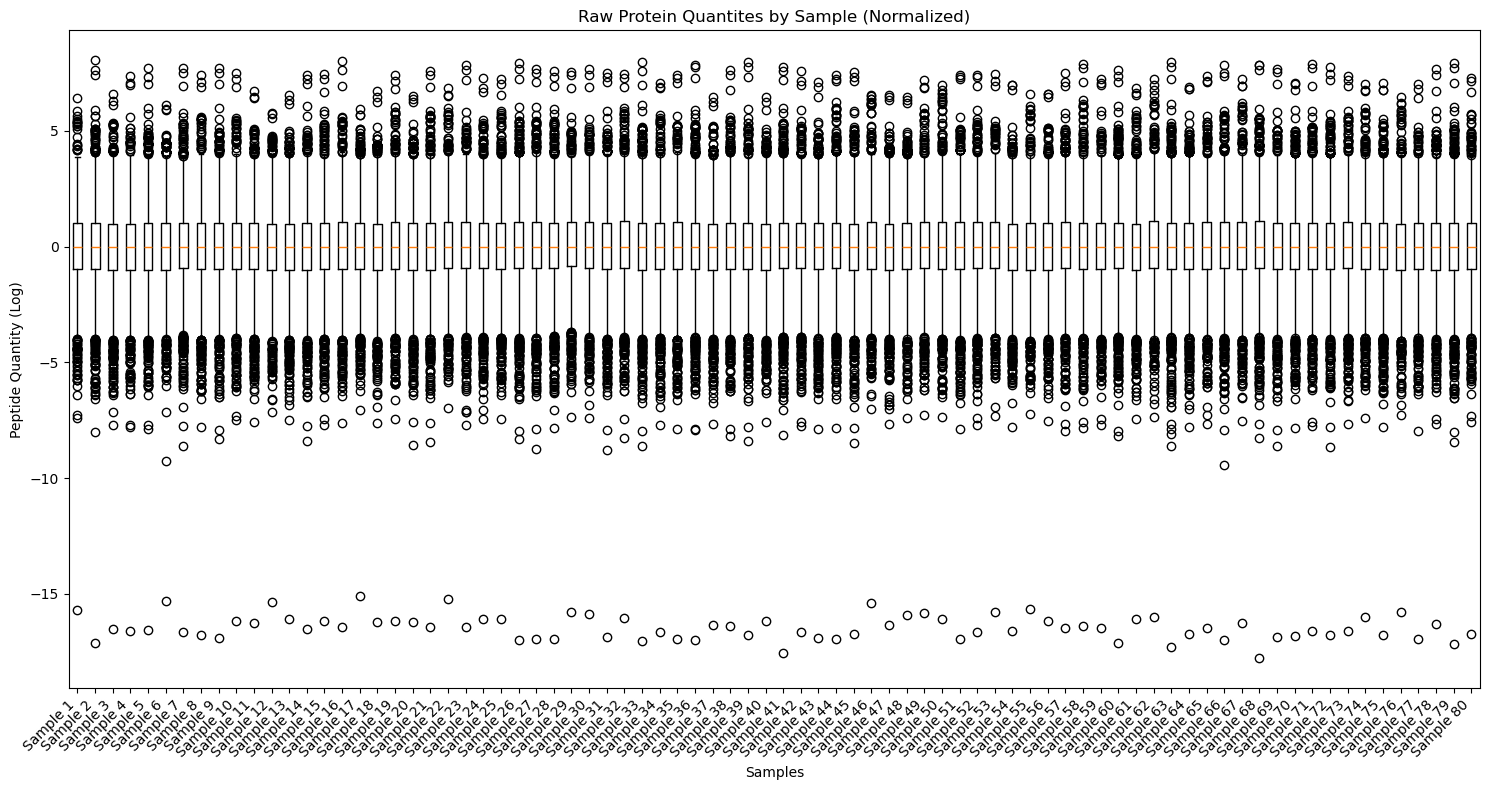

In [26]:
# Create the box plot
plt.figure(figsize=(15, 8))
plt.boxplot(X.T)  # Transpose the data

plt.title('Raw Protein Quantites by Sample (Normalized)')
plt.xlabel('Samples')
plt.ylabel('Peptide Quantity (Log)')
plt.xticks(range(1, X.shape[0] + 1), [f'Sample {i+1}' for i in range(X.shape[0])], rotation=45, ha='right')

plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.show()

/tmp/ipykernel_1697953/3615899121.py:13: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(data=mad_series, shade=True)


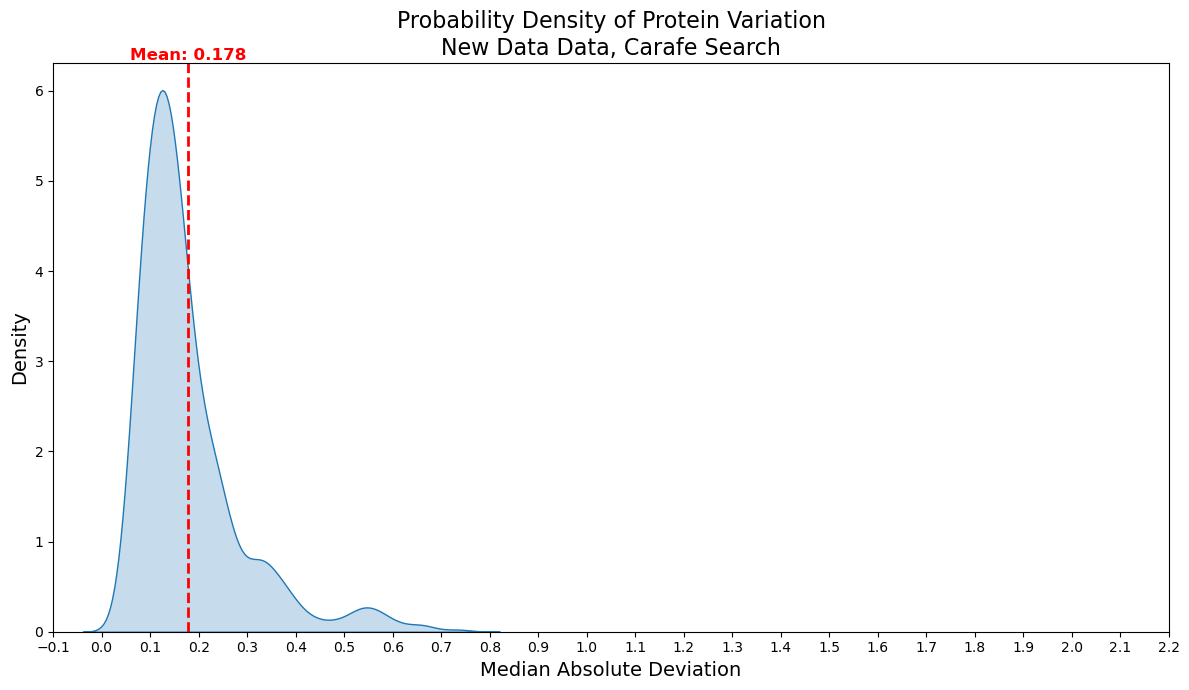

In [27]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import median_abs_deviation

mad = median_abs_deviation(X, axis=0)
mad_series = pd.Series(mad, name='Median Absolute Deviation')
mean_mad = np.mean(mad)

# Plot the probability density
plt.figure(figsize=(12, 7))
sns.kdeplot(data=mad_series, shade=True)

plt.title('Probability Density of Protein Variation\nNew Data Data, Carafe Search', fontsize=16)
plt.xlabel('Median Absolute Deviation', fontsize=14)
plt.ylabel('Density', fontsize=14)

plt.xlim(-0.1, 2.2)
plt.xticks(np.arange(-0.1, 2.3, 0.1))

plt.axvline(mean_mad, color='red', linestyle='--', linewidth=2)

plt.text(mean_mad, plt.ylim()[1], f'Mean: {mean_mad:.3f}', 
         horizontalalignment='center', verticalalignment='bottom',
         color='red', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()

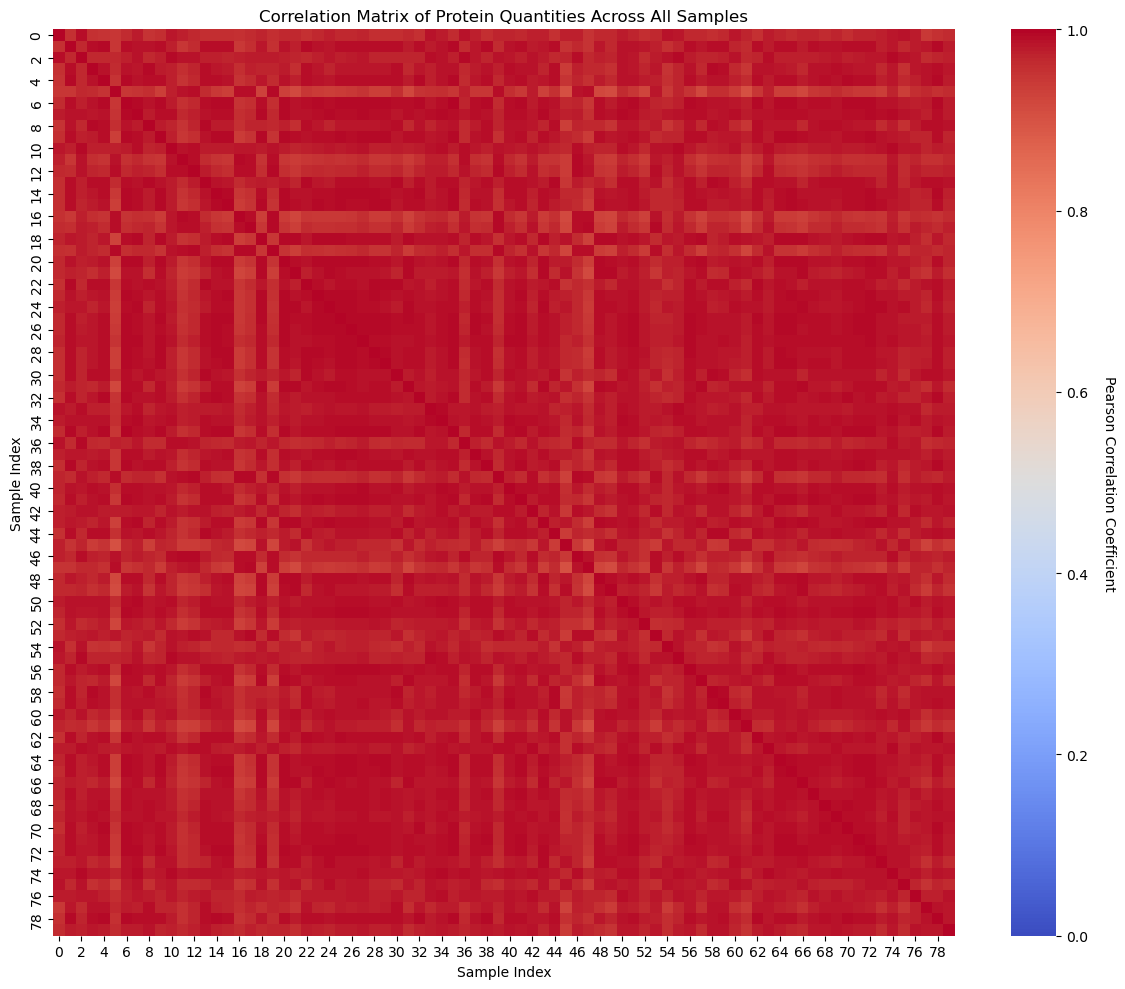

Number of samples: 80
Number of proteins: 1306
Using unlogged values
Average correlation (excluding self-correlations): 0.9772


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

def plot_protein_correlation_matrix(unlogged_X, use_log=True, save_path=None):
    """
    Create a correlation matrix heatmap comparing protein quantities across all samples.
    
    Parameters:
    unlogged_X (np.array): 2D array with samples as rows, proteins as columns, and quantities as values
    use_log (bool, optional): Whether to use log-transformed values for protein quantities. Defaults to True.
    save_path (str, optional): Path to save the plot. If None, the plot will be displayed instead.
    
    Returns:
    np.array: The correlation matrix
    """
    
    # Apply log transformation if use_log is True
    tmpX = np.log2(unlogged_X) if use_log else unlogged_X
    
    # Compute the correlation matrix
    corr_matrix = np.corrcoef(tmpX)
    
    # Create the heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(corr_matrix, cmap='coolwarm', center=0.5, vmin=0, vmax=1)
    
    plt.title('Correlation Matrix of Protein Quantities Across All Samples')
    plt.xlabel('Sample Index')
    plt.ylabel('Sample Index')
    
    # Add colorbar label
    cbar = plt.gcf().axes[-1]
    cbar.set_ylabel('Pearson Correlation Coefficient', rotation=270, labelpad=20)
    
    plt.tight_layout()
    
    # Save or display the plot
    if save_path:
        plt.savefig(save_path)
        plt.close()
    else:
        plt.show()
    
    # Print summary statistics
    print(f"Number of samples: {tmpX.shape[0]}")
    print(f"Number of proteins: {tmpX.shape[1]}")
    print(f"Using {'log-transformed' if use_log else 'unlogged'} values")
    
    # Calculate and print the average correlation, excluding self-correlations
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
    upper_triangle = corr_matrix[mask]
    average_correlation = np.mean(upper_triangle)
    print(f"Average correlation (excluding self-correlations): {average_correlation:.4f}")
    
    return corr_matrix

corr_matrix = plot_protein_correlation_matrix(X, use_log=False)

In [29]:
features = pd.read_csv(targets_fname, sep='\t')
idxs = []
for idx,protein in enumerate(protein_names):
  f = features[features['Protein'] == protein]
  if len(f) > 0:
    idxs.append(idx)
print(len(idxs))
top_protein_names = protein_names[idxs]
s_idxs = np.argsort(top_protein_names)
sorted_names = top_protein_names[s_idxs]
idxs = np.array(idxs)[s_idxs]

91


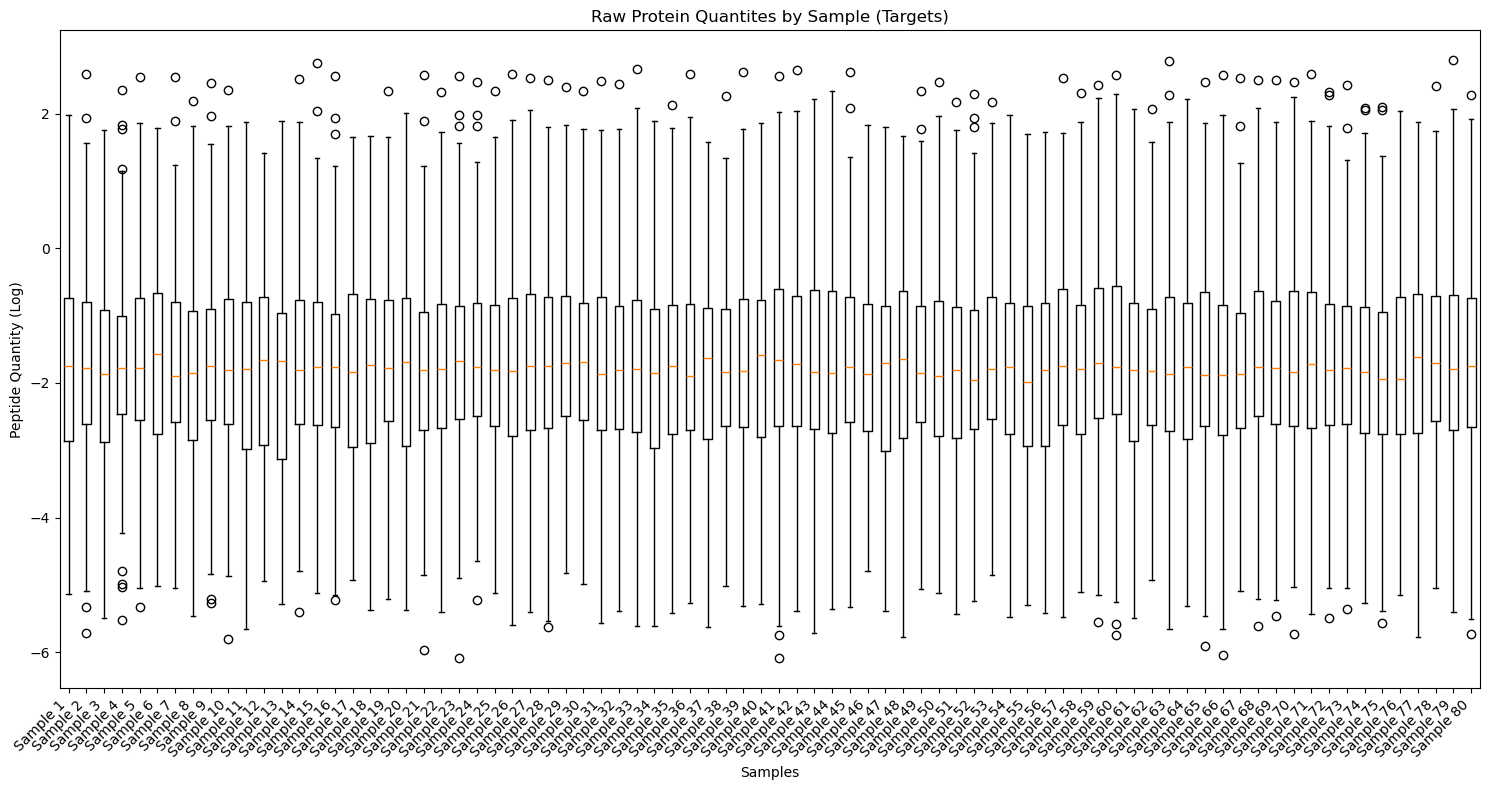

In [30]:
# Create the box plot
plt.figure(figsize=(15, 8))
plt.boxplot(X[:,idxs].T)  # Transpose the data

plt.title('Raw Protein Quantites by Sample (Targets)')
plt.xlabel('Samples')
plt.ylabel('Peptide Quantity (Log)')
plt.xticks(range(1, X.shape[0] + 1), [f'Sample {i+1}' for i in range(X.shape[0])], rotation=45, ha='right')

plt.tight_layout()  # Adjust layout to prevent clipping of labels
plt.show()

[ 0  0  0  0  0  0  0  0  0  0  0  0 75 75 75 75 75 75 65 65 65 65 55 55
 55 55 45 45 45 45 35 35 35 35 25 25 25 25 15 15 15 15  5  5  5  5 75 75
 75 75 75 75 65 65 65 65 55 55 55 55 45 45 45 45 35 35 35 35 25 25 25 25
 15 15 15 15  5  5  5  5]
Nieve MAE: 23.325


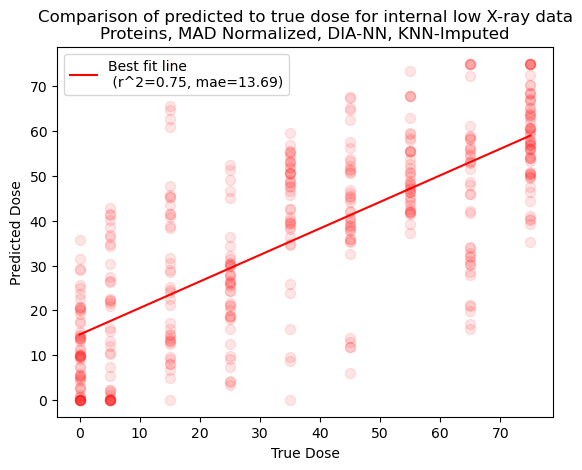

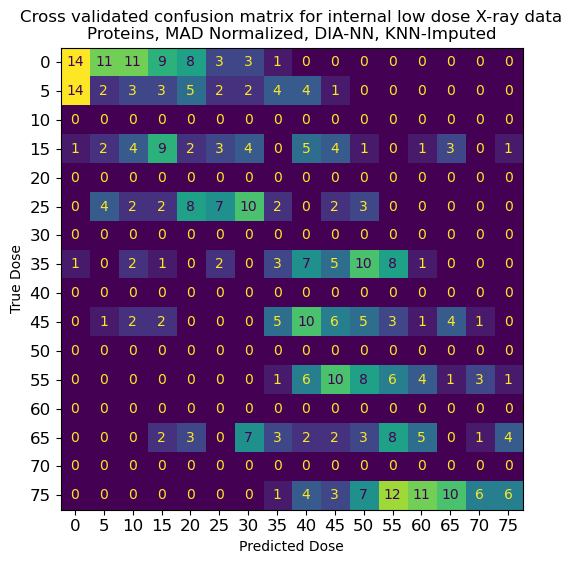

Number of proteins with all-zero coeffs: 48
Highest weighted protein: sp|Q9D379|HYEP_MOUSE



In [31]:
import scipy
import xgboost as xgb
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import RepeatedStratifiedKFold, RepeatedKFold
from sklearn.linear_model import ElasticNet, ElasticNetCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Normalizer

labeled_X = X[[r >= 0 for r in rad]][:,idxs]
y = rad[[r >= 0 for r in rad]]

print(y)

m = sum(y)/len(y)
print("Nieve MAE:", sum([np.abs(x-m) for x in y])/len(y))

pred_i = []
true_i = []
all_coeffs = []
all_coeffs_nonzero = []

splits = 10
repeats = 5
skf = RepeatedKFold(n_splits=splits, n_repeats = repeats, random_state=1966)
for train, test in skf.split(labeled_X, y):
  X_train, X_test, y_train, y_test = labeled_X[train], labeled_X[test], y[train], y[test]

  ss = StandardScaler()
  ss.fit(X_train)

  reg = ElasticNet(random_state=1966, max_iter = 500000, selection = 'cyclic', alpha = .5, l1_ratio = 1)

  reg.fit(ss.transform(X_train), y_train)

  if len(all_coeffs) == 0:
    all_coeffs = reg.coef_
    all_coeffs_nonzero = (reg.coef_ != 0).astype(int)
  else:
    all_coeffs += reg.coef_
    all_coeffs_nonzero += (reg.coef_ != 0).astype(int)


  pred_i += [x for x in reg.predict(ss.transform(X_test))]
  true_i += [x for x in y_test]

pred_i = [min(75, max(x,0)) for x in pred_i]

# write the predictions out
np.savetxt('regression_cv_fold_test_predictions.txt', np.column_stack((pred_i, true_i)), delimiter='\t', header='Predicted\tTrue', comments='')

plt.scatter(true_i, pred_i, c='r', s=52, alpha=0.1)
b, a, r_value, p_value, std_err = scipy.stats.linregress(true_i, pred_i)
xseq = np.linspace(min(true_i), max(true_i), num=2)
plt.plot(xseq, a + b * xseq, c = 'r', label = f'Best fit line \n (r^2={round(r_value,2)}, mae={round(np.mean([np.abs(x - y) for x,y in zip(pred_i, true_i)]),2)})')
plt.legend()
plt.xlabel('True Dose')
plt.ylabel('Predicted Dose')
plt.title('Comparison of predicted to true dose for internal low X-ray data\nProteins, MAD Normalized, DIA-NN, KNN-Imputed')
plt.show()

means = []
true = []
errors = []
for d in set(true_i):
  p = np.array(pred_i)[true_i == d]
  means.append(np.mean(p))
  errors.append(np.std(p))
  true.append(d)

# plt.errorbar(true, means, errors, linestyle='None', fmt='o', capsize = 5, ecolor='black', color='red', label = "Mean predicted dose (1 std. dev.)")

# b, a, r_value, p_value, std_err = scipy.stats.linregress(true_i, pred_i)
# xseq = np.linspace(min(true_i), max(true_i), num=2)
# plt.plot(xseq, a + b * xseq, c = 'r', label = f'Best fit line \n (r^2={round(r_value,2)}, mae={round(np.mean([np.abs(x - y) for x,y in zip(pred_i, true_i)]),2)})')
# plt.legend()
# plt.xlabel('True Dose')
# plt.ylabel('Average Predicted Dose')
# plt.title('Comparison of predicted to true dose for internal low dose X-ray data\nProteins, MAD Normalized, DIA-NN, KNN-Imputed')
# plt.show()

y_preds = []
for x in pred_i:
  if x < 0.5:
    y_preds.append(0)
  else:
    y_preds.append(int((2.5+x)/5)*5)

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(true_i, y_preds, ax=ax, colorbar=False)
ax.tick_params(axis='both', which='major', labelsize=12)
ax.set_xlabel("Predicted Dose")
ax.set_ylabel("True Dose")
ax.set_title('Cross validated confusion matrix for internal low dose X-ray data\nProteins, MAD Normalized, DIA-NN, KNN-Imputed')
plt.show()

print("Number of proteins with all-zero coeffs:", sum(all_coeffs < 1E-12))
print("Highest weighted protein:", sorted_names[np.argmax(all_coeffs)])
print()
# print("Proteins with non-zero coefficients:")
# for p in sorted_names[all_coeffs > 1E-12]:
#   print(p)

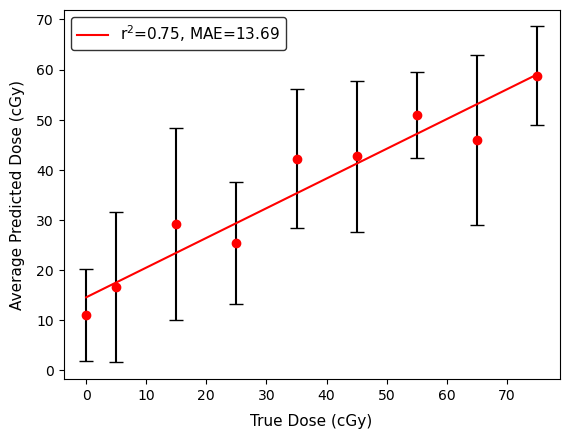

In [33]:
mae = np.mean([np.abs(x - y) for x,y in zip(pred_i, true_i)])

plt.errorbar(true, means, errors, 
             linestyle='None', fmt='o', capsize = 5, ecolor='black', color='red')

b, a, r_value, p_value, std_err = scipy.stats.linregress(true_i, pred_i)
xseq = np.linspace(min(true_i), max(true_i), num=2)
plt.plot(xseq, a + b * xseq, c = 'r', 
         label = f'r$^2$={round(r_value,2)}, MAE={round(mae,2)}')
plt.legend()
leg = plt.legend( 
            edgecolor="black", 
            prop={"size":11}, 
            #bbox_to_anchor=(1.02, 1.029),
)
plt.xlabel('True Dose (cGy)', size=11, labelpad=8)
plt.ylabel('Average Predicted Dose (cGy)', size=11, labelpad=8)
#plt.title('Comparison of predicted to true dose for internal low dose X-ray data\nProteins, MAD Normalized, DIA-NN, KNN-Imputed')
#plt.show()
plt.savefig("../figures/regression-plot-knn-imputed.pdf", bbox_inches="tight")